In [1]:
import os, sys

# Make the notebook runnable both interactively (from the repo root) and via
# `jupyter nbconvert --execute` (kernel cwd = experiments/).
if not os.path.isdir(os.path.join(os.getcwd(), 'tskan')):
    _root = os.path.abspath(os.path.join(os.getcwd(), '..'))
    os.chdir(_root)
    sys.path.insert(0, _root)


# TSKAN on LIVE-Netflix-II (Netflix Plus)

Trains the TSKAN model (paper, Sections III-V) on the LIVE-Netflix-II dataset:
DFT frequency-domain features (F=1: DC magnitude, first-frequency magnitude and
phase per variable) followed by a 1-layer KAN readout, with top-k=10 feature
selection based on the KAN input importance scores.

- Sequence: 16 chunks x 6 variables (the 7th variable, video height, is dropped)
- Scaling: `RobustScaler` (default quantile range), fitted on train only
- Stage 1: KAN `width=[18, 1]`, `grid=3`, `k=3`, `seed=9`, LBFGS, `lr=0.001`, 60 steps
- Stage 2: top-10 features, KAN `width=[10, 1]`, `grid=3`, `k=3`, `seed=5`, 40 steps

Run from the repository root: `python -m jupyter notebook experiments/01_tskan_netflix.ipynb`


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import mean_squared_error

from tskan.data import load_dataset
from tskan.features import dft_features, dft_feature_names
from tskan.model import TSKAN


In [3]:
# Processed splits: data/netflix2/netflixpluspadded_{TRAIN,VALID,TEST}.ts
data = load_dataset('netflix2', data_dir='data')
print('train', data['X_train'].shape, '| valid', data['X_valid'].shape, '| test', data['X_test'].shape)


train (282, 7, 16) | valid (54, 7, 16) | test (56, 7, 16)


In [4]:
# Drop the 7th variable (video height, constant within a session)
X_train = data['X_train'][:, :6, :]
X_valid = data['X_valid'][:, :6, :]
X_test  = data['X_test'][:, :6, :]
y_train, y_valid, y_test = data['y_train'], data['y_valid'], data['y_test']


In [5]:
# DFT features, F=1: per variable |X(0)|, |X(1)|, angle(X(1)) -> 6 x 3 = 18 features
X_train_f = dft_features(X_train)
X_valid_f = dft_features(X_valid)
X_test_f  = dft_features(X_test)
print('features:', X_train_f.shape[1])
feat_names = dft_feature_names(V=6, F=1)


features: 18


In [6]:
# Clean non-finite values and scale (fitted on train only)
X_train_f = np.nan_to_num(X_train_f, nan=0.0, posinf=0.0, neginf=0.0)
X_valid_f = np.nan_to_num(X_valid_f, nan=0.0, posinf=0.0, neginf=0.0)
X_test_f  = np.nan_to_num(X_test_f,  nan=0.0, posinf=0.0, neginf=0.0)

scaler = RobustScaler()
X_train_sc = scaler.fit_transform(X_train_f)
X_valid_sc = scaler.transform(X_valid_f)
X_test_sc  = scaler.transform(X_test_f)


## (Optional) Hyperparameter search

The paper selected lr / steps / seed by validating the stage-1 KAN (grid=3, k=3
fixed); the grid below is the one used. It takes on the order of an hour on CPU
and can be skipped: the best configuration found (lr=0.001, 60 steps, seed=9)
is used in the next cells.


In [7]:
# best_loss = float('inf')
# best = {}
# for lr in [1, 0.1, 0.01, 0.001, 0.0001]:
#     for seed in range(10):
#         for steps in [10, 20, 30, 40, 50]:
#             m = TSKAN(18, grid=3, k=3, seed=seed, device='cpu')
#             m.fit(X_train_sc, y_train, X_valid_sc, y_valid, steps=steps, lr=lr)
#             val_loss = m.train_history['test_loss'][-1]
#             if val_loss < best_loss:
#                 best_loss, best = val_loss, dict(lr=lr, seed=seed, steps=steps)
# print('best config:', best, 'val_loss:', best_loss)


In [8]:
# Stage 1: 1-layer KAN on all 18 DFT features
model = TSKAN(18, grid=3, k=3, seed=9, device='cpu')
model.fit(X_train_sc, y_train, X_valid_sc, y_valid, steps=60, lr=0.001)


description:   0%|                                                           | 0/60 [00:00<?, ?it/s]

| train_loss: 4.47e-01 | test_loss: 3.87e-01 | reg: 0.00e+00 | :   0%|       | 0/60 [00:00<?, ?it/s]

| train_loss: 4.47e-01 | test_loss: 3.87e-01 | reg: 0.00e+00 | :   2%| | 1/60 [00:00<00:50,  1.16it/

| train_loss: 2.38e-01 | test_loss: 2.72e-01 | reg: 0.00e+00 | :   2%| | 1/60 [00:00<00:50,  1.16it/

| train_loss: 2.38e-01 | test_loss: 2.72e-01 | reg: 0.00e+00 | :   3%| | 2/60 [00:00<00:24,  2.38it/

| train_loss: 2.12e-01 | test_loss: 2.49e-01 | reg: 0.00e+00 | :   3%| | 2/60 [00:01<00:24,  2.38it/

... (96 outputs left out)

| train_loss: 1.45e-01 | test_loss: 1.86e-01 | reg: 0.00e+00 | :  97%|▉| 58/60 [00:07<00:00,  6.98it

| train_loss: 1.45e-01 | test_loss: 1.86e-01 | reg: 9.68e+00 | :  97%|▉| 58/60 [00:07<00:00,  6.98it

| train_loss: 1.45e-01 | test_loss: 1.86e-01 | reg: 9.68e+00 | : 100%|█| 60/60 [00:07<00:00,  8.27it

| train_loss: 1.45e-01 | test_loss: 1.86e-01 | reg: 9.68e+00 | : 100%|█| 60/60 [00:07<00:00,  8.05it

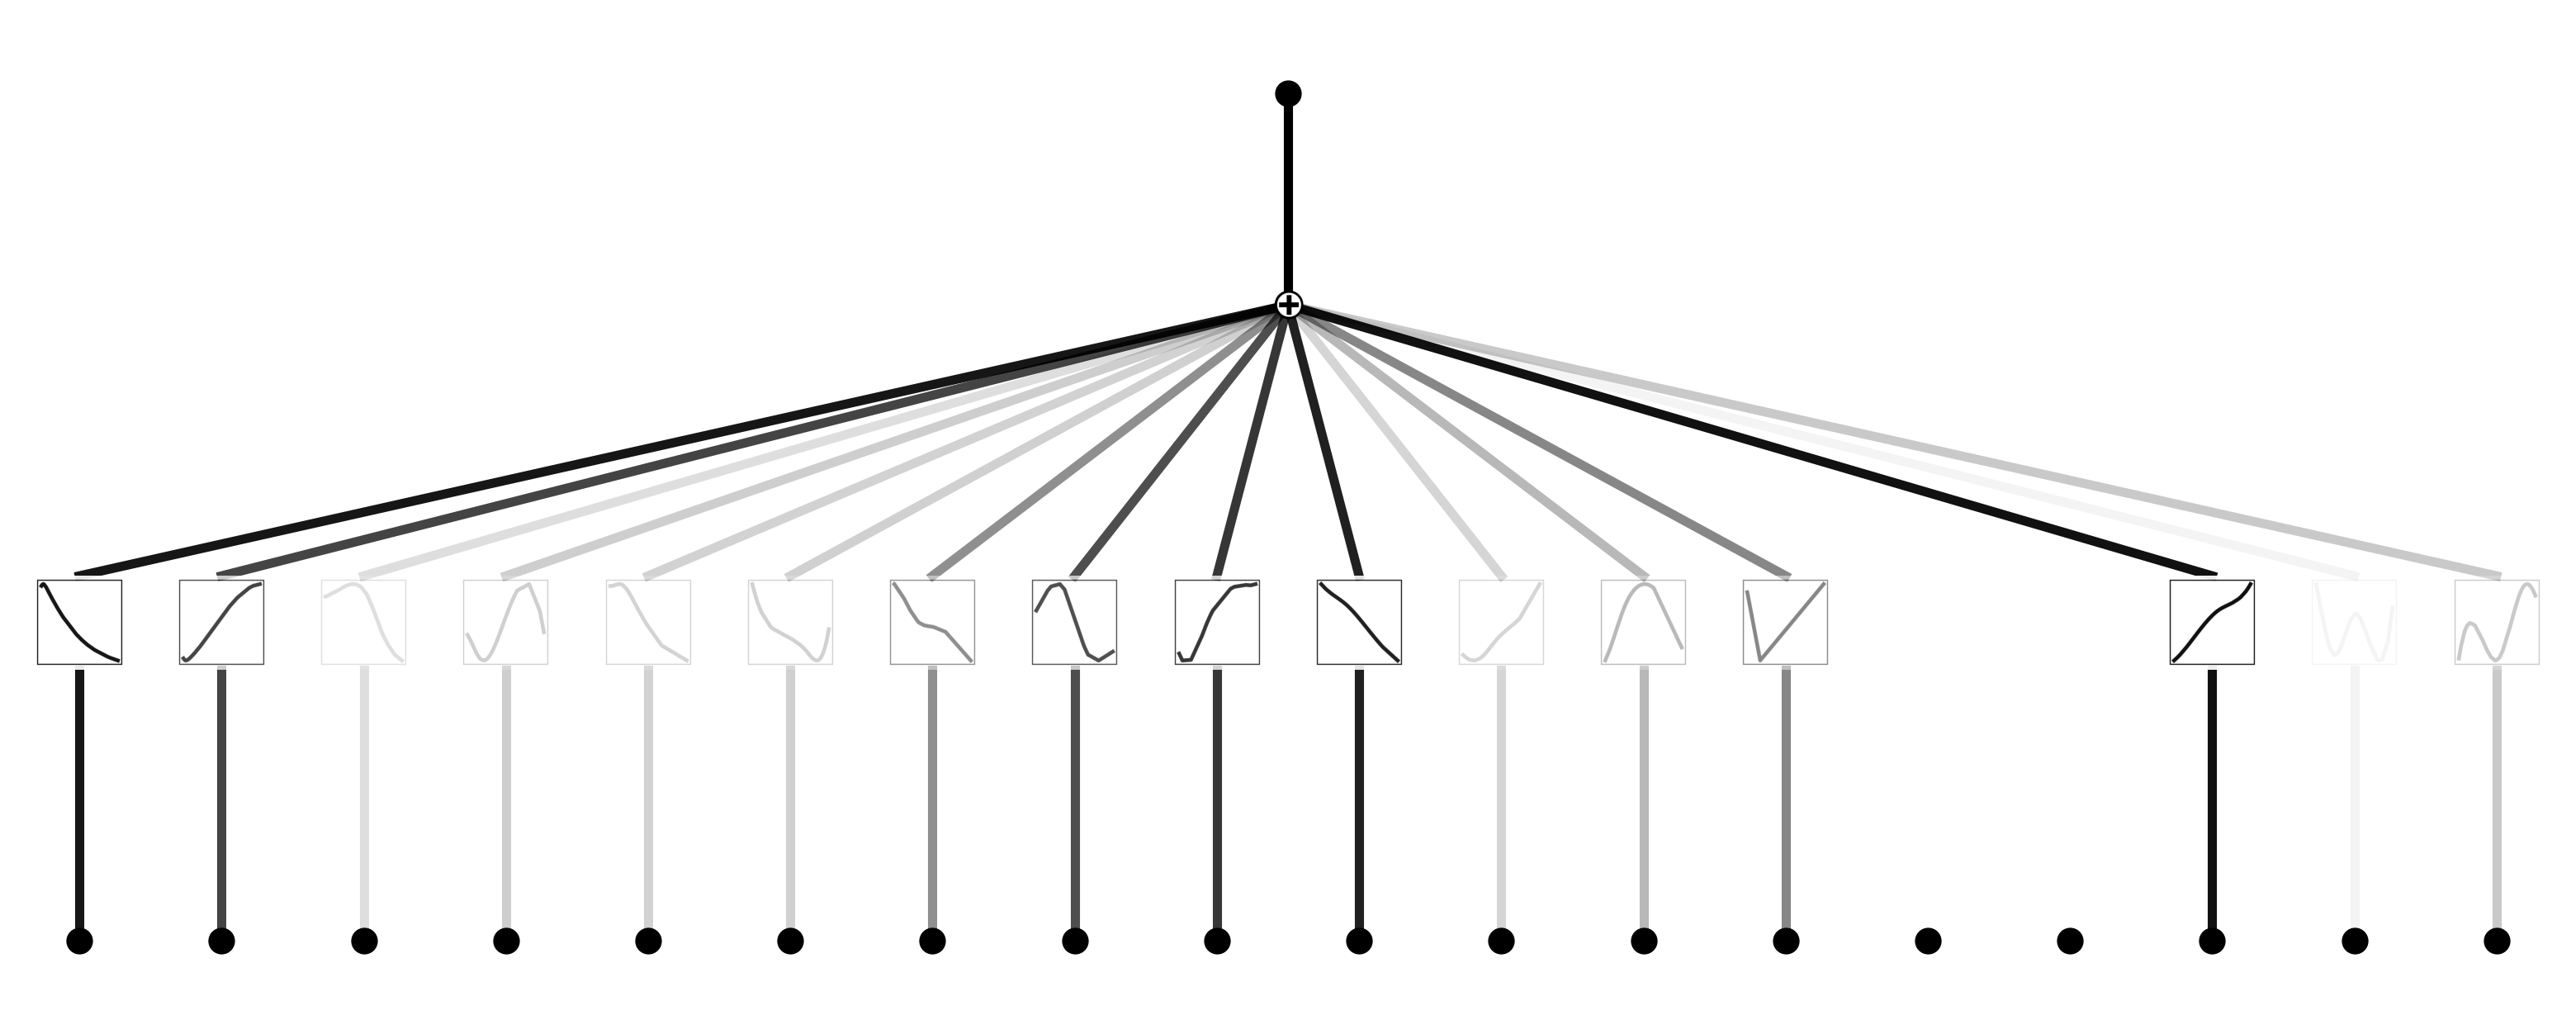

In [9]:
# Learned univariate activation functions of the KAN readout
model.plot(scale=4)


In [10]:
# Input importance scores alpha_j (paper, Section III-C)
model.importance


tensor([0.5186, 0.3127, 0.0434, 0.0644, 0.0593, 0.0615, 0.1575, 0.2852, 0.3547,
        0.4530, 0.0557, 0.0947, 0.1705, 0.0000, 0.0000, 0.5660, 0.0150, 0.0721])

Text(0.5, 1.0, 'Stage 1 (18 features)')

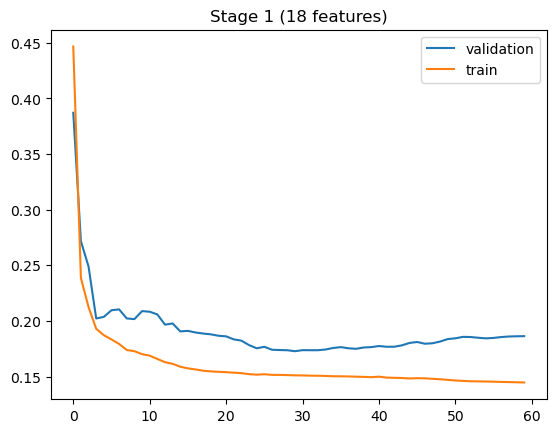

In [11]:
plt.plot(model.train_history['test_loss'], label='validation')
plt.plot(model.train_history['train_loss'], label='train')
plt.legend(); plt.title('Stage 1 (18 features)')


In [12]:
# Top-k selection: keep the k features with the highest importance
topk = model.top_k_indices(k=10)
topk


array([ 0,  1,  6,  7,  8,  9, 11, 12, 15, 17])

In [13]:
[feat_names[i] for i in topk]


['M_rebuffering_duration(0)',
 'M_rebuffering_duration(1)',
 'M_chunk_duration(0)',
 'M_chunk_duration(1)',
 'phase_chunk_duration(1)',
 'M_qp(0)',
 'phase_qp(1)',
 'M_framerate(0)',
 'M_width(0)',
 'phase_width(1)']

In [14]:
# Stage 2: 1-layer KAN on the top-10 features only
model = TSKAN(10, grid=3, k=3, seed=5, device='cpu')
model.fit(X_train_sc[:, topk], y_train, X_valid_sc[:, topk], y_valid, steps=40, lr=0.001)


description:   0%|                                                           | 0/40 [00:00<?, ?it/s]

| train_loss: 3.68e-01 | test_loss: 3.56e-01 | reg: 0.00e+00 | :   0%|       | 0/40 [00:00<?, ?it/s]

| train_loss: 3.68e-01 | test_loss: 3.56e-01 | reg: 0.00e+00 | :   2%| | 1/40 [00:00<00:05,  6.53it/

| train_loss: 2.42e-01 | test_loss: 2.90e-01 | reg: 0.00e+00 | :   2%| | 1/40 [00:00<00:05,  6.53it/

| train_loss: 2.42e-01 | test_loss: 2.90e-01 | reg: 0.00e+00 | :   5%| | 2/40 [00:00<00:04,  8.10it/

| train_loss: 2.08e-01 | test_loss: 2.36e-01 | reg: 0.00e+00 | :   5%| | 2/40 [00:00<00:04,  8.10it/

... (54 outputs left out)

| train_loss: 1.56e-01 | test_loss: 1.99e-01 | reg: 0.00e+00 | :  95%|▉| 38/40 [00:03<00:00, 10.90it

| train_loss: 1.56e-01 | test_loss: 1.98e-01 | reg: 8.95e+00 | :  95%|▉| 38/40 [00:03<00:00, 10.90it

| train_loss: 1.56e-01 | test_loss: 1.98e-01 | reg: 8.95e+00 | : 100%|█| 40/40 [00:03<00:00, 11.03it

| train_loss: 1.56e-01 | test_loss: 1.98e-01 | reg: 8.95e+00 | : 100%|█| 40/40 [00:03<00:00, 11.10it

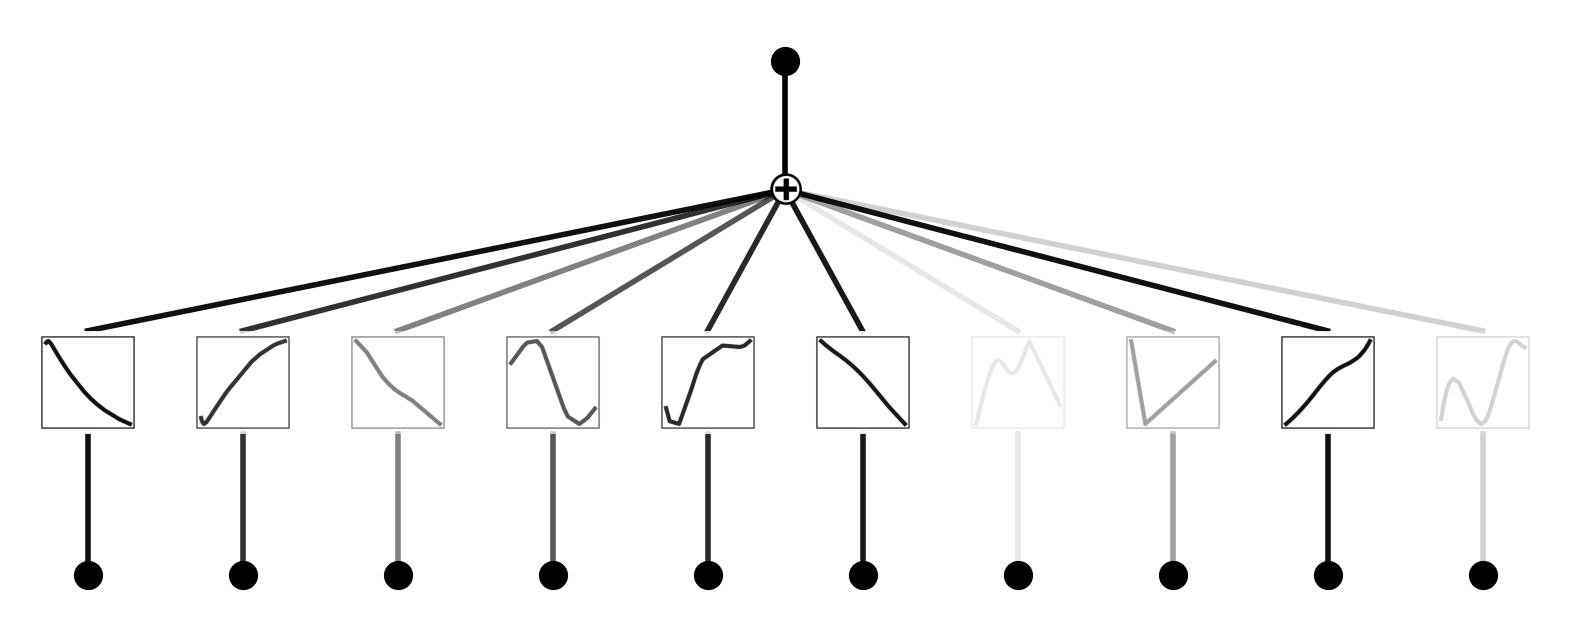

In [15]:
model.plot(scale=2)


Text(0.5, 1.0, 'Stage 2 (top-10 features)')

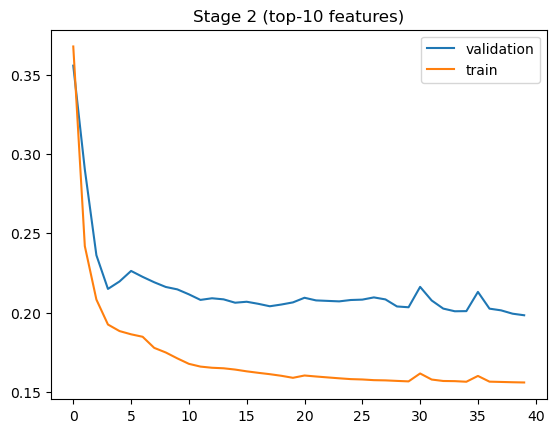

In [16]:
plt.plot(model.train_history['test_loss'], label='validation')
plt.plot(model.train_history['train_loss'], label='train')
plt.legend(); plt.title('Stage 2 (top-10 features)')


TSKAN test RMSE (LIVE-Netflix-II): 0.22516968517309754


Text(0, 0.5, 'predicted')

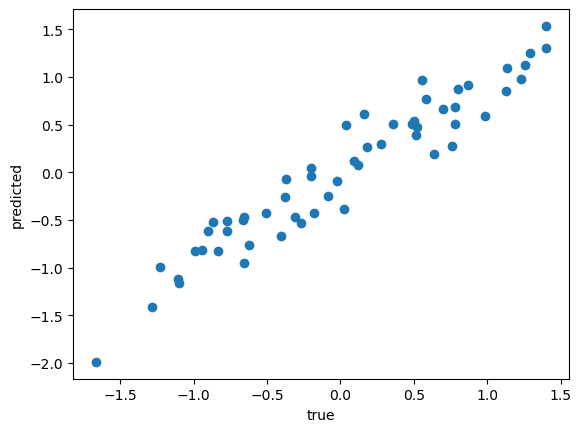

In [17]:
# Test set evaluation
y_pred = model.predict(X_test_sc[:, topk])
rmse = float(np.sqrt(mean_squared_error(y_test, y_pred)))
print('TSKAN test RMSE (LIVE-Netflix-II):', rmse)
plt.scatter(y_test, y_pred)
plt.xlabel('true'); plt.ylabel('predicted')


In [18]:
print('number of trainable parameters:', model.n_params())


number of trainable parameters: 120


**Expected results** (paper, Tables I-II): TSKAN test RMSE = **0.2169** on
LIVE-Netflix-II with **120** trainable parameters. Small differences can occur
across torch/pykan versions.


## Effect of phase on a periodic signal (paper, Fig. 5)

TSKAN is sensitive to *when* a quality event occurs within the session: the
first-frequency phase of a DFT feature encodes the timing of periodic
distortions. The figure below shows a cosine with one cycle over the 16
chunks of a session at different phase shifts; the paper's
`figures/fig3_phase_effects.svg` shows how the TSKAN prediction moves with
the phase of the rebuffering signal.



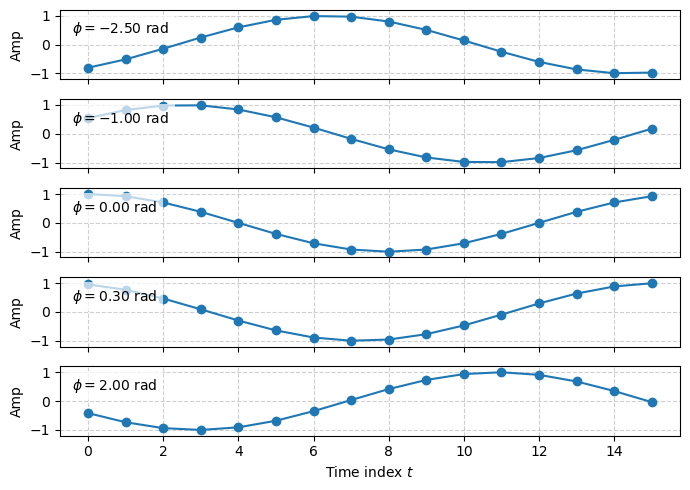

In [19]:
import matplotlib.pyplot as plt

# Number of time points
T = 16
t = np.arange(T)

# Frequency index (1 cycle over 16 samples, i.e. k=1 in the DFT)
freq = 1
omega = 2 * np.pi * freq / T

# Different phase shifts (in radians)
phases = [-2.5, -1, 0, 0.3, 2]

# Create vertically stacked subplots
fig, axes = plt.subplots(len(phases), 1, figsize=(7, 5), sharex=True)

for ax, phi in zip(axes, phases):
    x = np.cos(omega * t + phi)
    ax.plot(t, x, marker='o', color='C0')
    ax.set_ylabel("Amp")
    ax.set_ylim(-1.2, 1.2)
    ax.grid(True, linestyle='--', alpha=0.6)

    # Add subtitle inside the plot (top-left corner)
    ax.text(0.02, 0.85,
            fr'$\phi = {phi:.2f}$ rad',
            transform=ax.transAxes,
            fontsize=10,
            ha='left', va='top',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

axes[-1].set_xlabel("Time index $t$")

plt.tight_layout()
plt.show()
